# Part 1: Monte Carlo (MC) estimation of the bias of an estimator (about 45 min)

**Motivation** In nuclear medicine (PET, SPECT) we reconstruct an activity image $\mathbf{x}$ from Poisson-distributed counts
$\mathbf{y}$ measured along lines of response (LORs), e.g. with an ML reconstruction such as MLEM/OSEM. For quantitative imaging
(e.g. the uptake in a lesion) we need to know whether the reconstruction is **biased**: is the expected reconstructed activity equal to
the true activity? For realistic reconstructions this cannot be calculated by hand. Instead, we simulate many noise realisations of
the data, reconstruct each of them, and average: a **Monte Carlo study**. Since every realisation costs a full reconstruction, we
must also know **how many realisations** we need. Here we learn this on tiny "scanners" with two voxels, where everything runs in seconds.

**Learning goals.** After this session you can

1. estimate the (relative) bias of an estimator with MC and quantify the uncertainty of this MC estimate with its standard error (SE),
2. explain how the SE scales with the number of realisations $N$ (Part 1),
3. decide with an interval and a margin whether a bias exceeds a tolerance, and plan $N$ with a quick pilot run (Part 1),
4. apply this workflow to a non-linear estimator whose bias depends on the true activities, keeping the run time in mind (Part 2).

**How to use the notebooks.** Every code cell starts with a tag:

| tag | what to do |
|---|---|
| `# [RUN]` | run the cell **without changes** |
| `# [FUNCTIONS]` | run the cell **without changes** (it only defines functions) |
| `# [CHANGE]` | change the variable marked with `# <-- CHANGE ME`, then run the cell (possibly several times) |
| `# [CALCULATE]` | enter your own short calculation (only in Part 2, two cells) |

**Time plan (120 min):** intro 15 min, Part 1 about 45 min, Part 2 about 35 min (Part A 20 min, Part B 15 min), finishing the Toledo test 15 min, wrap-up 10 min. Answer the Toledo questions **while you work**: each question names the step it refers to.

The **Reflection** boxes summarise what to take away from a step; the arrows (→ Toledo Q…) point to the questions of the Toledo test.

## Imaging system 1: two voxels, two LORs

We study a tiny "scanner" with two voxels (unknown activities $x_1$, $x_2$) and two lines of response (LORs).
LOR 1 passes through both voxels, LOR 2 only through voxel 1. The detected counts are independent Poisson variables:

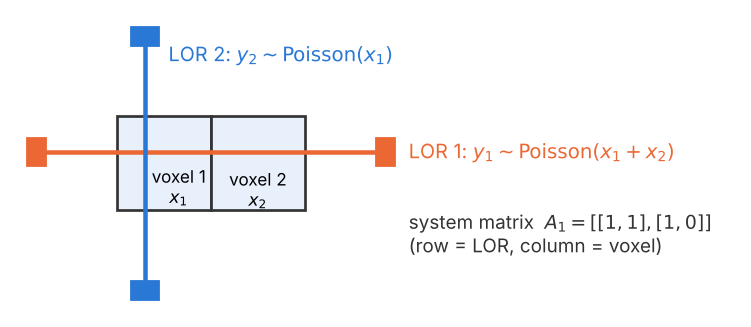

$$
\mathbf{y} \sim \mathrm{Poisson}(A_1\mathbf{x}), \qquad
A_1 = \begin{pmatrix}1 & 1\\ 1 & 0\end{pmatrix}
\quad\Longleftrightarrow\quad
y_1 \sim \mathrm{Poisson}(x_1 + x_2), \quad y_2 \sim \mathrm{Poisson}(x_1) .
$$

Each row of the system matrix belongs to one LOR, each column to one voxel. The ML estimate (maximum of the Poisson log-likelihood) is

$$\hat{x}_1 = y_2, \qquad \hat{x}_2 = y_1 - y_2 .$$

In [ ]:
# [RUN]
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

# ONE random number generator for the whole notebook:
# every call of simulate_system1 gives NEW random numbers,
# and re-running the whole notebook gives the same results
rng = np.random.default_rng(seed=42)

In [ ]:
# [FUNCTIONS]
def simulate_system1(x1, x2, N, rng):
    """Simulate N noise realisations of imaging system 1: y1 ~ Poisson(x1 + x2), y2 ~ Poisson(x1).

    x1, x2: true activities of voxel 1 and voxel 2
    N:      number of noise realisations
    rng:    numpy random number generator
    returns: (y1, y2), two integer arrays of length N (counts in LOR 1 and LOR 2)
    """
    y1 = rng.poisson(x1 + x2, N)
    y2 = rng.poisson(x1, N)

    return y1, y2


def ml_estimator_system1(y1, y2):
    """ML estimate for imaging system 1: x1_hat = y2, x2_hat = y1 - y2.

    y1, y2: counts (numbers, or arrays of length N with one value per realisation)
    returns: (x1_hat, x2_hat), same type and length as the input
    """
    x1_hat = y2
    x2_hat = y1 - y2

    return x1_hat, x2_hat

## Step 1: a naive first try

We simulate only $N = 10$ noise realisations. From every single realisation $k$ we get an estimate $\hat{x}_j^{(k)}$, and with it a
(very noisy) **estimate of the relative bias from that single realisation**,

$$\hat{r}_j^{(k)} = \frac{\hat{x}_j^{(k)} - x_j}{x_j} .$$

The mean of these $N$ values is our **MC estimate of the relative bias**, $\hat{r}_j = \frac{1}{N}\sum_k \hat{r}_j^{(k)}$.

In [ ]:
# [RUN]
x1_true = 100.0
x2_true = 50.0

N = 10


y1, y2 = simulate_system1(x1_true, x2_true, N, rng)    # simulated counts, two arrays of length N

x1_hat, x2_hat = ml_estimator_system1(y1, y2)          # estimates, two arrays of length N


# estimated relative bias from every single realisation
rel_bias_single_x1 = (x1_hat - x1_true) / x1_true
rel_bias_single_x2 = (x2_hat - x2_true) / x2_true


print("  k | x1_hat   rel. bias (single) | x2_hat   rel. bias (single)")
print("--------------------------------------------------------------")

for k in range(N):
    print(f"{k:3d} | {x1_hat[k]:6.0f}   {rel_bias_single_x1[k]:+10.4f}         |"
          f" {x2_hat[k]:6.0f}   {rel_bias_single_x2[k]:+10.4f}")


# MC estimate of the relative bias = mean over the N realisations
rel_bias_x1 = np.mean(rel_bias_single_x1)
rel_bias_x2 = np.mean(rel_bias_single_x2)

print()
print(f"MC estimate of the relative bias of x1 (N = {N}): {rel_bias_x1:+.4f}")
print(f"MC estimate of the relative bias of x2 (N = {N}): {rel_bias_x2:+.4f}")

**Reflection.** Our tolerance for the relative bias is $0.01$. Run the cell a few times (new random numbers each time) and compare
the MC estimates of the relative bias with this tolerance. A single MC estimate is only useful if we also know how uncertain it is,
and how this uncertainty depends on $N$ (next steps). (→ Toledo Q1)

## Step 2: the MC estimate of the relative bias is itself a random number

From $N$ realisations we compute three MC estimates. Each of them has its own **standard error** (SE), i.e. the standard deviation
of the MC estimate over many repeated MC experiments. With the sample standard deviation $s_j$ of the $N$ estimates $\hat{x}_j^{(k)}$:

| quantity | MC estimate | its standard error |
|---|---|---|
| expectation $\mathbb{E}[\hat{x}_j]$ | $\bar{x}_j = \dfrac{1}{N}\displaystyle\sum_{k=1}^{N} \hat{x}_j^{(k)}$ | $\mathrm{SE}(\bar{x}_j) = \dfrac{s_j}{\sqrt{N}}$ |
| bias $b_j = \mathbb{E}[\hat{x}_j] - x_j$ | $\hat{b}_j = \bar{x}_j - x_j$ | $\mathrm{SE}(\hat{b}_j) = \mathrm{SE}(\bar{x}_j) = \dfrac{s_j}{\sqrt{N}}$ |
| relative bias $r_j = b_j / x_j$ | $\hat{r}_j = \dfrac{\hat{b}_j}{x_j}$ | $\mathrm{SE}(\hat{r}_j) = \dfrac{\mathrm{SE}(\hat{b}_j)}{x_j} = \dfrac{s_j}{x_j\sqrt{N}}$ |

(Subtracting the constant $x_j$ does not change the spread; dividing by the constant $x_j$ divides the spread by $x_j$.)

**In this notebook, every SE and every RMSE refers to the MC estimate of the relative bias**, $\hat{r}_j$. The code uses the names
`SE_rel_bias_x1`, `SE_rel_bias_x2` (and `RMSE_rel_bias_x1`, `RMSE_rel_bias_x2` in step 4).

In the cell below we **repeat** the whole MC experiment (with $N$ realisations each) `num_runs` times and plot a histogram of the
`num_runs` values of $\hat{r}_j$. The spread of this histogram is $\mathrm{SE}(\hat{r}_j)$. The red lines mark the tolerance $\pm 0.01$.

Change `N` (10, 100, 1000, 10000) and run the cell again. Observe how the spread of the histograms changes with $N$. (→ Toledo Q2)

In [ ]:
# [CHANGE]
N = 1000             # <-- CHANGE ME: 10, 100, 1000, 10000
num_runs = 200

threshold = 0.01     # tolerance for the relative bias


rel_bias_x1_runs = np.zeros(num_runs)     # one MC estimate of the relative bias per run
rel_bias_x2_runs = np.zeros(num_runs)

for i_run in range(num_runs):

    y1, y2 = simulate_system1(x1_true, x2_true, N, rng)

    x1_hat, x2_hat = ml_estimator_system1(y1, y2)

    rel_bias_x1_runs[i_run] = np.mean((x1_hat - x1_true) / x1_true)
    rel_bias_x2_runs[i_run] = np.mean((x2_hat - x2_true) / x2_true)


# the spread of the MC estimates over the runs is the SE of the relative bias
SE_rel_bias_x1_runs = np.std(rel_bias_x1_runs)
SE_rel_bias_x2_runs = np.std(rel_bias_x2_runs)

print(f"N = {N}: spread of the {num_runs} MC estimates of the relative bias (= SE of the relative bias)")
print(f"   SE_rel_bias_x1: {SE_rel_bias_x1_runs:.5f}")
print(f"   SE_rel_bias_x2: {SE_rel_bias_x2_runs:.5f}")


xmax = max(0.05, np.max(np.abs(rel_bias_x1_runs)), np.max(np.abs(rel_bias_x2_runs)))
bins = np.linspace(-xmax, xmax, 41)           # same bins for both histograms

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")

ax[0].hist(rel_bias_x1_runs, bins=bins, color="#2a78d6")
ax[1].hist(rel_bias_x2_runs, bins=bins, color="#eb6834")

for j in range(2):
    ax[j].axvline(-threshold, color="red", ls=":")
    ax[j].axvline(+threshold, color="red", ls=":")
    ax[j].set_xlabel("MC estimate of the relative bias")
    ax[j].set_ylabel("number of runs")

ax[0].set_title(f"x1, N = {N}")
ax[1].set_title(f"x2, N = {N}")
plt.show()

## Step 3: the expected answer (pen and paper)

The ML estimator for imaging system 1 is linear, so we can compute its expectation and variance exactly:

* $\mathbb{E}[\hat{x}_1] = x_1$ and $\mathbb{E}[\hat{x}_2] = x_2$: the true relative bias is $r_1 = r_2 = 0$,
* $\mathrm{Var}(\hat{x}_1) = x_1$ and $\mathrm{Var}(\hat{x}_2) = 2x_1 + x_2$, i.e. $\sigma_1 = \sqrt{x_1}$ and $\sigma_2 = \sqrt{2x_1 + x_2}$.

In [ ]:
# [RUN]
known_rel_bias_x1 = 0.0
known_rel_bias_x2 = 0.0

known_sigma_x1 = np.sqrt(x1_true)
known_sigma_x2 = np.sqrt(2 * x1_true + x2_true)

print("known relative bias of x1:", known_rel_bias_x1)
print("known relative bias of x2:", known_rel_bias_x2)
print()
print(f"known sigma_1 / x1: {known_sigma_x1 / x1_true:.4f}")
print(f"known sigma_2 / x2: {known_sigma_x2 / x2_true:.4f}")

## Step 4: how does the error of the MC estimate scale with $N$?

For each $N$ we repeat the MC experiment `num_runs` times and compute the **root-mean-square error** (RMSE) of the
MC estimates $\hat{r}_j$ of the relative bias around the known value $r_j$:

$$\mathrm{RMSE}(\hat{r}_j) = \sqrt{\frac{1}{\text{num\_runs}} \sum_{\text{runs}} \big(\hat{r}_j - r_j\big)^2 } .$$

This averages over the runs, so we see the *typical* error of one MC estimate, not the error of one lucky or unlucky run.

We expect a power law $\mathrm{RMSE} \approx C\,N^{p}$. Taking the logarithm gives $\ln \mathrm{RMSE} = p \ln N + \ln C$, so in a plot of
$\ln \mathrm{RMSE}$ versus $\ln N$ the points lie on a straight line with **slope $p$**. Read off the slope. (→ Toledo Q2)

In [ ]:
# [RUN]
Ns = [10, 100, 1000, 10000]
num_runs = 1000


RMSE_rel_bias_x1 = np.zeros(len(Ns))
RMSE_rel_bias_x2 = np.zeros(len(Ns))

for i_N in range(len(Ns)):

    N = Ns[i_N]

    rel_bias_x1_runs = np.zeros(num_runs)
    rel_bias_x2_runs = np.zeros(num_runs)

    for i_run in range(num_runs):

        y1, y2 = simulate_system1(x1_true, x2_true, N, rng)

        x1_hat, x2_hat = ml_estimator_system1(y1, y2)

        rel_bias_x1_runs[i_run] = np.mean((x1_hat - x1_true) / x1_true)
        rel_bias_x2_runs[i_run] = np.mean((x2_hat - x2_true) / x2_true)

    # typical error of ONE MC estimate of the relative bias: root mean square over the runs
    RMSE_rel_bias_x1[i_N] = np.sqrt(np.mean((rel_bias_x1_runs - known_rel_bias_x1) ** 2))
    RMSE_rel_bias_x2[i_N] = np.sqrt(np.mean((rel_bias_x2_runs - known_rel_bias_x2) ** 2))


print("     N |  ln N | RMSE_rel_bias_x1  ln(...) | RMSE_rel_bias_x2  ln(...)")
print("------------------------------------------------------------------------")

for i_N in range(len(Ns)):
    print(f"{Ns[i_N]:6d} | {np.log(Ns[i_N]):5.2f} |      {RMSE_rel_bias_x1[i_N]:.5f}     {np.log(RMSE_rel_bias_x1[i_N]):+7.3f} |"
          f"      {RMSE_rel_bias_x2[i_N]:.5f}     {np.log(RMSE_rel_bias_x2[i_N]):+7.3f}")


fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")

ax.plot(np.log(Ns), np.log(RMSE_rel_bias_x1), "o-", color="#2a78d6", label="x1")
ax.plot(np.log(Ns), np.log(RMSE_rel_bias_x2), "o-", color="#eb6834", label="x2")

ax.set_xlabel("ln N")
ax.set_ylabel("ln RMSE of the MC estimate of the relative bias")
ax.minorticks_on()
ax.grid(True, which="minor", alpha=0.1)
ax.legend()
plt.show()

## Step 5: one MC experiment knows its own uncertainty

Step 4 needed `num_runs` repetitions. In practice we run only **one** MC experiment. Its standard error
$\mathrm{SE}(\hat{r}_j) = s_j / (x_j\sqrt{N})$ (step 2) predicts the same typical error, without any repetitions and without knowing
the true answer.

(For very small $N$, such as $N = 10$, the sample standard deviation $s_j$ is itself quite uncertain, so the SE of a single run is only a
rough estimate there.) (→ Toledo Q2)

In [ ]:
# [RUN]
SE_rel_bias_x1 = np.zeros(len(Ns))
SE_rel_bias_x2 = np.zeros(len(Ns))

for i_N in range(len(Ns)):

    N = Ns[i_N]

    y1, y2 = simulate_system1(x1_true, x2_true, N, rng)          # ONE MC experiment

    x1_hat, x2_hat = ml_estimator_system1(y1, y2)

    SE_rel_bias_x1[i_N] = np.std(x1_hat, ddof=1) / (x1_true * np.sqrt(N))
    SE_rel_bias_x2[i_N] = np.std(x2_hat, ddof=1) / (x2_true * np.sqrt(N))


print("     N | SE_rel_bias_x1 (1 run)  RMSE_rel_bias_x1 | SE_rel_bias_x2 (1 run)  RMSE_rel_bias_x2")
print("------------------------------------------------------------------------------------------")

for i_N in range(len(Ns)):
    print(f"{Ns[i_N]:6d} |        {SE_rel_bias_x1[i_N]:.5f}             {RMSE_rel_bias_x1[i_N]:.5f}     |"
          f"        {SE_rel_bias_x2[i_N]:.5f}             {RMSE_rel_bias_x2[i_N]:.5f}")

## Step 6: how many realisations do we need? (pilot run)

**Decision rule.** We use the interval $\hat{r}_j \pm 2\,\mathrm{SE}(\hat{r}_j)$ (it contains the true value with probability ≈ 0.95) and compare it with the
tolerance band $[-0.01, 0.01]$:

* whole interval **outside** the band: $|r_j| > 0.01$,
* whole interval **inside** the band: $|r_j| < 0.01$,
* interval **contains** the threshold: undecided, we need more realisations.

**Why a margin?** If the true relative bias were exactly at the threshold, no finite $N$ could ever decide. We therefore only ask
for a reliable decision if the true bias is at least a **margin** $m$ away from the threshold (here $m = 0.005$, i.e. $|r_j| \ge 0.015$
or $|r_j| \le 0.005$).

**How small must the SE be?** Two things can bring the interval closer to the threshold:

1. the MC estimate $\hat{r}_j$ itself scatters around the true value $r_j$: in an unlucky run it lies $2\,\mathrm{SE}$ closer to the threshold,
2. the interval then reaches another $2\,\mathrm{SE}$ further towards the threshold.

So the interval stays on the correct side of the threshold (even in an unlucky run) if $4\,\mathrm{SE}(\hat{r}_j) \le m$:

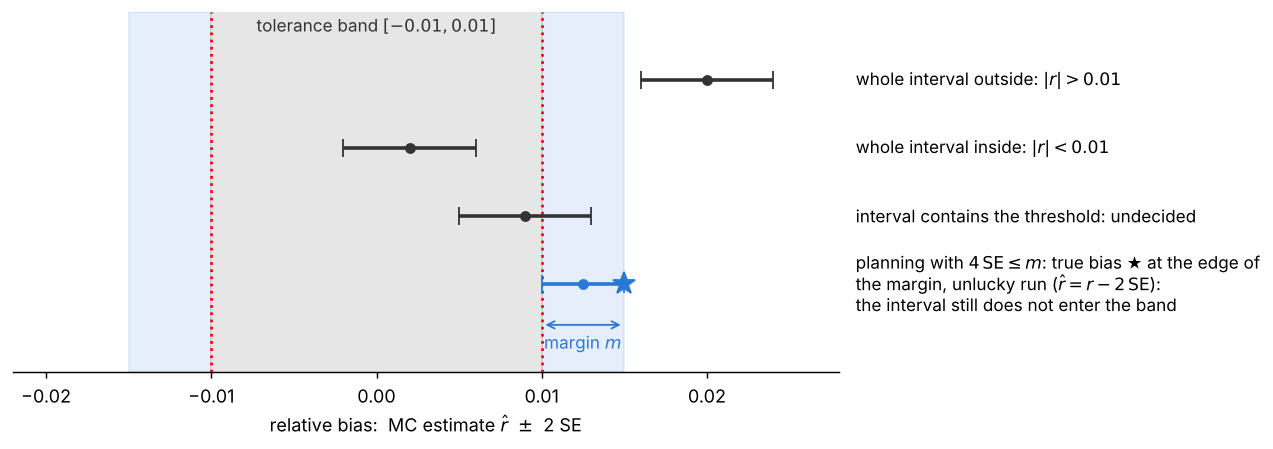

With $\mathrm{SE}(\hat{r}_j) = s_j/(x_j\sqrt{N})$ this gives

$$ N \ge \left(\frac{4\, s_j / x_j}{m}\right)^2 .$$

For our linear estimator we know $\sigma_j$ (step 3). **For most estimators we do not know $\sigma_j$ in advance.** In practice we therefore
first run a single, quick **pilot run** (e.g. $N = 1000$) to estimate $s_j$, and then use it to choose $N$ for the final run.

In [ ]:
# [RUN]
N_pilot = 1000
margin = 0.005


y1, y2 = simulate_system1(x1_true, x2_true, N_pilot, rng)        # pilot run

x1_hat, x2_hat = ml_estimator_system1(y1, y2)


rel_sd_x1 = np.std(x1_hat, ddof=1) / x1_true                 # estimated s_1 / x1
rel_sd_x2 = np.std(x2_hat, ddof=1) / x2_true                 # estimated s_2 / x2

N_needed_x1 = (4 * rel_sd_x1 / margin) ** 2
N_needed_x2 = (4 * rel_sd_x2 / margin) ** 2


print(f"pilot run: s_1 / x1 = {rel_sd_x1:.4f}   (known: {known_sigma_x1 / x1_true:.4f})")
print(f"pilot run: s_2 / x2 = {rel_sd_x2:.4f}   (known: {known_sigma_x2 / x2_true:.4f})")
print()
print(f"needed N for x1: {N_needed_x1:.0f}")
print(f"needed N for x2: {N_needed_x2:.0f}")
print(f"-> use N = {max(N_needed_x1, N_needed_x2):.0f} for the final run")

**Reflection.** The pilot run with $N = 1000$ is far too small to decide whether $|r_j| > 0.01$, but it is good enough to estimate
$s_j / x_j$, which is all we need for planning. Compare the planned $N$ for $x_1$ and $x_2$ with their relative standard deviations
$s_j/x_j$, and note how the planned $N$ depends on the margin $m$. (→ Toledo Q3, Q4, Q5)

## Step 7: can we also detect a real bias?

So far the estimator was unbiased. To check that our workflow also detects a **real** bias, we scale the ML estimates:

$$\tilde{x}_1 = 0.985\,\hat{x}_1, \qquad \tilde{x}_2 = 1.015\,\hat{x}_2 .$$

Since the ML estimator is unbiased, we know the answer upfront: $\mathbb{E}[\tilde{x}_1] = 0.985\,x_1$ and
$\mathbb{E}[\tilde{x}_2] = 1.015\,x_2$, so the true relative biases are $r_1 = -0.015$ and $r_2 = +0.015$, both larger than the
tolerance $0.01$ in magnitude.

**Your task: choose $N$.** How large must $N$ be such that one MC experiment shows $|r_j| > 0.01$ for both parameters?
Think before you run:

* the true relative biases are only $0.005$ beyond the threshold, i.e. exactly at the edge of the margin $m$ of step 6,
* the interval $\hat{r}_j \pm 2\,\mathrm{SE}(\hat{r}_j)$ must lie completely outside the tolerance band,
* the MC estimate $\hat{r}_j$ itself scatters around the true value by about $\pm 2\,\mathrm{SE}(\hat{r}_j)$ (step 2),
* $\mathrm{SE}(\hat{r}_j) = s_j / (x_j\sqrt{N})$, and you know $s_j / x_j$ from step 6
  (the scaling by 0.985 and 1.015 hardly changes it).

The cell below starts with $N = 1000$, which is too small. Change `N` to the value you think is sufficient and run the cell again.
Choose $N$ as small as possible: for real problems (e.g. one full image reconstruction per noise realisation) every realisation can
take seconds to minutes.

To *see* what could happen in one MC experiment, the cell repeats the experiment `num_runs` times (in practice you run it only once).
The histograms show the `num_runs` MC estimates $\hat{r}_j$ (grey: tolerance band, light blue: margin $m = 0.005$ next to the band,
black line: known value). Above each histogram, the intervals $\hat{r}_j \pm 2\,\mathrm{SE}(\hat{r}_j)$ of the **first three runs** are drawn
(each of them is what you could see in practice).
(Since the cell repeats the experiment 100 times, large $N$ such as $10^6$ takes several seconds.)

In [ ]:
# [FUNCTIONS]
def biased_estimator_system1(y1, y2):
    """Scaled ML estimator for imaging system 1: x1_tilde = 0.985 * x1_hat, x2_tilde = 1.015 * x2_hat."""
    x1_hat, x2_hat = ml_estimator_system1(y1, y2)

    x1_tilde = 0.985 * x1_hat
    x2_tilde = 1.015 * x2_hat

    return x1_tilde, x2_tilde

In [ ]:
# [CHANGE]
N = 1000             # <-- CHANGE ME: choose N yourself (as small as possible, but large enough)
num_runs = 100       # repetitions, only to visualise what could happen in ONE MC experiment

threshold = 0.01     # tolerance for the relative bias
margin = 0.005       # margin (step 6)


rel_bias_x1_runs = np.zeros(num_runs)     # MC estimate of the relative bias, one value per run
rel_bias_x2_runs = np.zeros(num_runs)

SE_rel_bias_x1_runs = np.zeros(num_runs)  # its standard error, one value per run
SE_rel_bias_x2_runs = np.zeros(num_runs)

for i_run in range(num_runs):

    y1, y2 = simulate_system1(x1_true, x2_true, N, rng)

    x1_tilde, x2_tilde = biased_estimator_system1(y1, y2)

    rel_bias_x1_runs[i_run] = np.mean((x1_tilde - x1_true) / x1_true)
    rel_bias_x2_runs[i_run] = np.mean((x2_tilde - x2_true) / x2_true)

    SE_rel_bias_x1_runs[i_run] = np.std(x1_tilde, ddof=1) / (x1_true * np.sqrt(N))
    SE_rel_bias_x2_runs[i_run] = np.std(x2_tilde, ddof=1) / (x2_true * np.sqrt(N))


print(f"N = {N}")
print()
print("first three runs (each of them is what you could see in practice):")
print()

for i_run in range(3):
    print(f"run {i_run + 1}:  x1: rel. bias = {rel_bias_x1_runs[i_run]:+.5f},  2 * SE_rel_bias_x1 = {2 * SE_rel_bias_x1_runs[i_run]:.5f}"
          f"  |  x2: rel. bias = {rel_bias_x2_runs[i_run]:+.5f},  2 * SE_rel_bias_x2 = {2 * SE_rel_bias_x2_runs[i_run]:.5f}")

print()
print(f"known relative biases: x1: -0.015,  x2: +0.015      tolerance band: [-0.01, +0.01]      margin: {margin}")


all_values = np.concatenate([rel_bias_x1_runs, rel_bias_x2_runs])
xmax = max(0.03, np.max(np.abs(all_values)) + 2 * np.max(SE_rel_bias_x2_runs) + 0.006)
bins = np.linspace(-xmax, xmax, 121)          # same bins for both histograms

fig, ax = plt.subplots(1, 2, figsize=(11, 5.5), layout="constrained")

counts_x1, _, _ = ax[0].hist(rel_bias_x1_runs, bins=bins, color="#2a78d6", label="all runs")
counts_x2, _, _ = ax[1].hist(rel_bias_x2_runs, bins=bins, color="#eb6834", label="all runs")


# first three runs, drawn above the histogram: point with error bar = rel. bias +- 2 SE
for i_run in range(3):

    y_x1 = (1.15 + 0.15 * i_run) * np.max(counts_x1)
    y_x2 = (1.15 + 0.15 * i_run) * np.max(counts_x2)

    if i_run == 0:
        label_SE = "rel. bias +- 2 SE (runs 1, 2, 3)"
    else:
        label_SE = None

    ax[0].errorbar(rel_bias_x1_runs[i_run], y_x1, xerr=2 * SE_rel_bias_x1_runs[i_run], fmt="o", color="black",
                   capsize=5, lw=2, label=label_SE)
    ax[1].errorbar(rel_bias_x2_runs[i_run], y_x2, xerr=2 * SE_rel_bias_x2_runs[i_run], fmt="o", color="black",
                   capsize=5, lw=2, label=label_SE)

    ax[0].text(rel_bias_x1_runs[i_run] + 2 * SE_rel_bias_x1_runs[i_run] + 0.001, y_x1, f"run {i_run + 1}",
               va="center", fontsize="small")
    ax[1].text(rel_bias_x2_runs[i_run] + 2 * SE_rel_bias_x2_runs[i_run] + 0.001, y_x2, f"run {i_run + 1}",
               va="center", fontsize="small")

ax[0].set_ylim(0, 1.6 * np.max(counts_x1))
ax[1].set_ylim(0, 1.6 * np.max(counts_x2))

ax[0].axvline(-0.015, color="black", lw=1, label="known value")
ax[1].axvline(+0.015, color="black", lw=1, label="known value")

for j in range(2):
    ax[j].axvspan(-threshold, threshold, color="grey", alpha=0.25, label="tolerance band")
    ax[j].axvspan(threshold, threshold + margin, color="#2a78d6", alpha=0.12, label="margin")
    ax[j].axvspan(-threshold - margin, -threshold, color="#2a78d6", alpha=0.12)
    ax[j].set_xlim(-xmax, xmax)
    ax[j].set_xlabel("MC estimate of the relative bias")
    ax[j].set_ylabel("number of runs")

for j in range(2):
    ax[j].legend(fontsize="small", loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)

ax[0].set_title(f"x1_tilde, N = {N}")
ax[1].set_title(f"x2_tilde, N = {N}")
plt.show()

**Reflection.** Note the $N$ you chose and how you estimated it before running the cell. With a good choice, the intervals of the first
three runs (and of almost all other runs in the histogram) lie completely outside the tolerance band, although the three runs differ
slightly. With $N = 1000$ they do not. Compare your $N$ with the $N$ planned in step 6: the true biases lie exactly at the edge of the
margin, which is the case the planning rule was made for. (→ Toledo Q6, Q7)

---
**End of Part 1.** Continue with the notebook of Part 2.